In [13]:
# Cell 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [14]:
# Cell 2: Generate synthetic datase
np.random.seed(42)

n = 1000

data = pd.DataFrame({

    "fitness_cost": np.random.uniform(0, 0.5, n),

    "relative_growth": np.random.uniform(0, 1, n),

    "phage_pressure": np.random.uniform(0, 1, n)

})

# Create an artificial mathematical rule

score = (
    data["relative_growth"]
    - data["fitness_cost"]
    - data["phage_pressure"]
    + np.random.normal(0, 0.15, n)
)

# Generate target labels

data["persistence"] = (score > -0.25).astype(int)

print("Dataset generated successfully!")

print("Total observations:", len(data))

Dataset generated successfully!
Total observations: 1000


In [15]:
# Cell 3: Inspect the dataset

print(data.head())

print("\nDataset Information:")

print(data.info())

print("\nStatistical Summary:")

print(data.describe())

print("\nTarget Distribution:")

print(data["persistence"].value_counts())

   fitness_cost  relative_growth  phage_pressure  persistence
0      0.187270         0.185133        0.261706            1
1      0.475357         0.541901        0.246979            1
2      0.365997         0.872946        0.906255            0
3      0.299329         0.732225        0.249546            1
4      0.078009         0.806561        0.271950            1

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   fitness_cost     1000 non-null   float64
 1   relative_growth  1000 non-null   float64
 2   phage_pressure   1000 non-null   float64
 3   persistence      1000 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 31.4 KB
None

Statistical Summary:
       fitness_cost  relative_growth  phage_pressure  persistence
count   1000.000000      1000.000000     1000.000000  1000.000000
mean       0.24

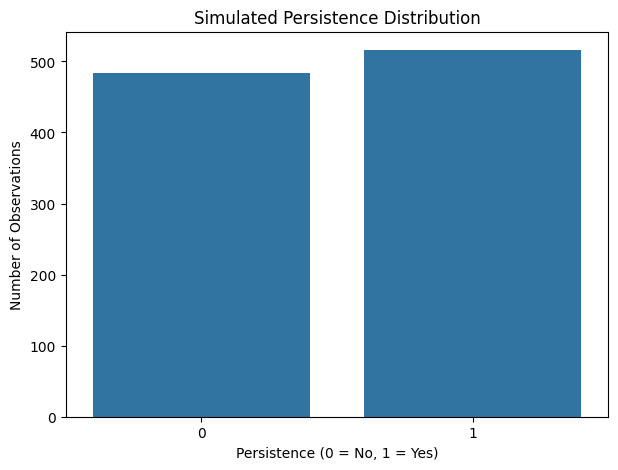

In [16]:
# Cell 4: Visualize the dataset

plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="persistence"
)

plt.title("Simulated Persistence Distribution")

plt.xlabel("Persistence (0 = No, 1 = Yes)")

plt.ylabel("Number of Observations")

plt.show()

In [17]:
# Cell 5: Prepare data and train the model

X = data[
    [
        "fitness_cost",
        "relative_growth",
        "phage_pressure"
    ]
]

y = data["persistence"]


# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# Create Random Forest model

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)


# Train the model

model.fit(X_train, y_train)


print("Model training completed!")

print("Training samples:", len(X_train))

print("Testing samples:", len(X_test))

Model training completed!
Training samples: 800
Testing samples: 200


In [18]:
# Cell 6: Evaluate model performance

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

precision = precision_score(
    y_test,
    predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predictions,
    zero_division=0
)


print("MODEL EVALUATION RESULTS")

print("-------------------------")

print("Accuracy:", round(accuracy, 4))

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

MODEL EVALUATION RESULTS
-------------------------
Accuracy: 0.915
Precision: 0.9388
Recall: 0.8932
F1 Score: 0.9154


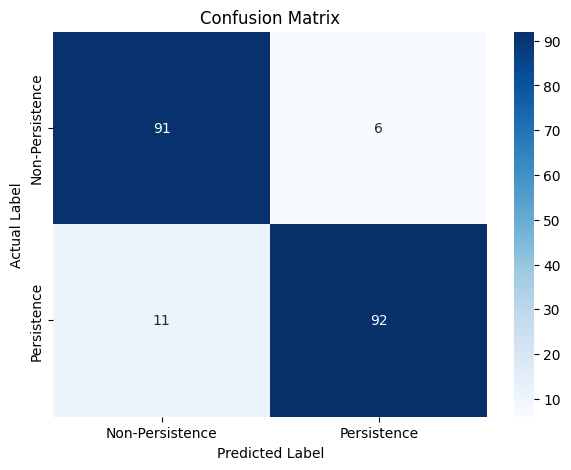

In [19]:
# Cell 7: Confusion Matrix

cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Non-Persistence",
        "Persistence"
    ],
    yticklabels=[
        "Non-Persistence",
        "Persistence"
    ]
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.show()

relative_growth    0.435724
phage_pressure     0.391541
fitness_cost       0.172735
dtype: float64


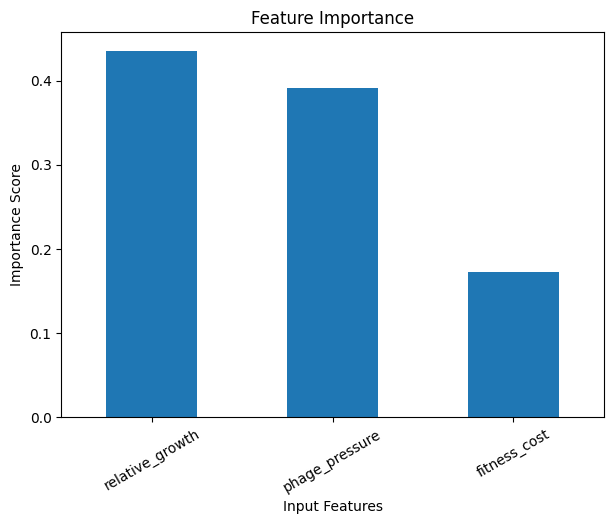

In [20]:
# Cell 8: Feature Importance

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
)

print(importance)

plt.figure(figsize=(7, 5))

importance.plot(kind="bar")

plt.title("Feature Importance")

plt.xlabel("Input Features")

plt.ylabel("Importance Score")

plt.xticks(rotation=30)

plt.show()

In [21]:
# Cell 9: Test a new synthetic observation

new_sample = pd.DataFrame({

    "fitness_cost": [0.20],

    "relative_growth": [0.65],

    "phage_pressure": [0.40]

})

prediction = model.predict(new_sample)

probability = model.predict_proba(new_sample)

print("Prediction:", prediction[0])

print("Class probabilities:", probability[0])

if prediction[0] == 1:

    print("Result: Simulated Persistence")

else:

    print("Result: Simulated Non-Persistence")

Prediction: 1
Class probabilities: [0.09385477 0.90614523]
Result: Simulated Persistence


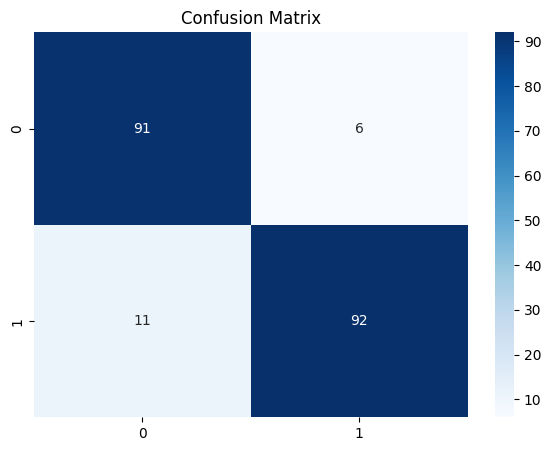

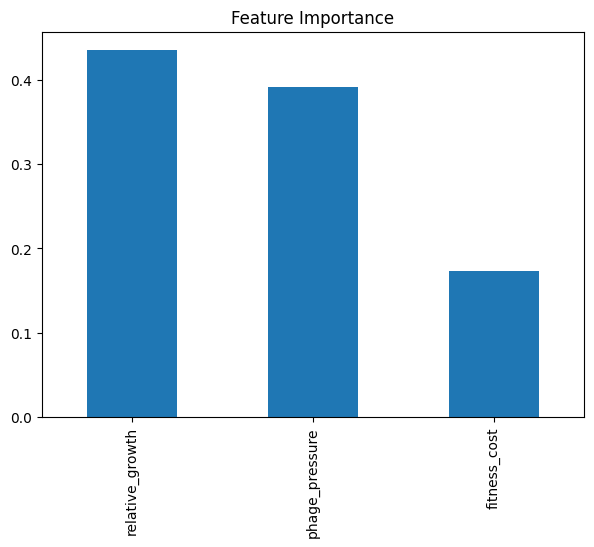

All results saved successfully!


In [22]:
# Cell 10: Save project results

import os

os.makedirs("results", exist_ok=True)

# Save dataset
data.to_csv(
    "results/synthetic_phage_data.csv",
    index=False
)

# Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

metrics.to_csv(
    "results/model_evaluation.csv",
    index=False
)

# Save confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")

plt.savefig(
    "results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save feature importance
plt.figure(figsize=(7, 5))

importance.plot(kind="bar")

plt.title("Feature Importance")

plt.savefig(
    "results/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All results saved successfully!")

In [23]:
# Additional analysis: Check possible overfitting

train_predictions = model.predict(X_train)

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

test_accuracy = accuracy_score(
    y_test,
    predictions
)

print("Training Accuracy:", train_accuracy)

print("Testing Accuracy:", test_accuracy)

print(
    "Accuracy Difference:",
    train_accuracy - test_accuracy
)

Training Accuracy: 0.94125
Testing Accuracy: 0.915
Accuracy Difference: 0.026249999999999996
